# Introduction: implementation

A tic-tac-toe player that learns state values with a temporal-difference (TD) update, checked
against the exact optimum and contrasted with direct policy search.
Companion to the chapter note: [Introduction](../chapters/01%20Introduction.md).

**Sections**
1. The game and an imperfect opponent
2. The exact answer by dynamic programming
3. The value-learning player
4. Evolutionary policy search as a contrast
5. An opponent that changes
6. Checkpoints

In [1]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_GAME, SEED_TD, SEED_EVO, SEED_CHANGE = 1, 3, 4, 10  # one seed per section
X, O = 1, 2  # we play X; the opponent plays O and moves first
EMPTY_BOARD = (0,) * 9
LINES = ((0, 1, 2), (3, 4, 5), (6, 7, 8), (0, 3, 6), (1, 4, 7), (2, 5, 8), (0, 4, 8), (2, 4, 6))
P_SMART = 0.5  # chance the opponent plays a winning or blocking move when one exists (toy choice)
EPS = 0.1
ALPHA = 0.1
N_GAMES = 20_000  # games of training per learner
BLOCK = 500  # games per point of a learning curve
GAMES_PER_POLICY = 100  # games used to judge one candidate policy in section 4
P_AFTER = 0.9  # the stricter opponent of section 5
N_SEEDS = 5  # repeated runs in section 5

## 1. The game and an imperfect opponent

Two players alternate on a three-by-three board; three marks in a row win, a full board is a draw.
We play X and, as in the chapter's figure of a game, the opponent moves first.
Draws and losses count the same for us: both are worth 0, a win is worth 1.

The opponent is imperfect: with probability `P_SMART` it takes a winning move if it has one,
otherwise blocks our winning move if we threaten one, and otherwise (or with the remaining
probability) plays a uniformly random legal move. The book does not specify its opponent, so this
is a toy choice. The learner never sees these probabilities.

In [2]:
def winner(b: tuple) -> int:
    """Mark that has three in a row on board `b`, or 0."""
    for i, j, k in LINES:
        if b[i] and b[i] == b[j] == b[k]:
            return b[i]
    return 0


def moves(b: tuple) -> list:
    return [i for i in range(9) if b[i] == 0]


def play(b: tuple, i: int, mark: int) -> tuple:
    return b[:i] + (mark,) + b[i + 1 :]


def terminal_value(b: tuple):
    """Our value of a finished board (1 win, 0 loss or draw), or None while the game goes on."""
    w = winner(b)
    if w:
        return 1.0 if w == X else 0.0
    return None if moves(b) else 0.0


def opponent_dist(b: tuple, p_smart: float) -> dict:
    """Probability of each legal O move on board `b`."""
    legal = moves(b)
    probs = {i: (1 - p_smart) / len(legal) for i in legal}
    for mark in (O, X):  # first win (O completes a line), then block (O takes X's winning square)
        forced = [i for i in legal if winner(play(b, i, mark)) == mark]
        if forced:
            for i in forced:
                probs[i] += p_smart / len(forced)
            return probs
    for i in legal:
        probs[i] += p_smart / len(legal)
    return probs


b = (O, 0, 0, 0, X, 0, 0, 0, O)  # O threatens nothing yet; X has the centre
print(
    "Opponent move probabilities (two O corners, X centre):",
    {i: round(p, 3) for i, p in opponent_dist(b, P_SMART).items()},
)
b = (O, O, 0, 0, X, 0, 0, 0, 0)  # O threatens the top row
print(
    "Opponent when it can win at square 2:", {i: round(p, 3) for i, p in opponent_dist(b, P_SMART).items() if p > 0.2}
)

Opponent move probabilities (two O corners, X centre): {1: 0.167, 2: 0.167, 3: 0.167, 5: 0.167, 6: 0.167, 7: 0.167}
Opponent when it can win at square 2: {2: 0.583}


### Reading the result

- With two O corners and X in the centre nobody threatens a win, so the opponent picks each of the 6 free squares with probability 1/6 (0.167).
- When it can complete a line at square 2 it takes that square with probability 0.583: the 0.5 of smart play plus its 1/6 share of the other 0.5 (spread over the 6 legal squares).

## 2. The exact answer by dynamic programming

Because we know the opponent here, we can compute the true value of every board *after our move*:
the probability of winning from there when we always play the best move.
The learner will not get this information; it serves only as truth to compare against.
The chapter notes that dynamic programming (computing values backward from the finished boards with a known model)
needs exactly this: the opponent's move probabilities in every board state.

$$
v_*(b) = \sum_{m} p(m \mid b)\, \max_{a}\, v_*\big(b \oplus m \oplus a\big)
$$

- $b$ is a board after our move and $m$ a legal opponent move with probability $p(m \mid b)$.
- $b \oplus m \oplus a$ is the board after the opponent plays $m$ and we reply with move $a$.
- Finished boards have value 1 (our win) or 0 (loss or draw); if the opponent's move finishes the game, that value replaces the maximum.
- The empty board is the position before the opponent's first move.

In [3]:
@lru_cache(maxsize=None)
def v_star(b: tuple, p_smart: float) -> float:
    """Exact win probability from board `b` (after our move, opponent to play) under optimal play."""
    t = terminal_value(b)
    if t is not None:
        return t
    total = 0.0
    for i, p in opponent_dist(b, p_smart).items():
        c = play(b, i, O)
        t = terminal_value(c)
        total += p * (t if t is not None else max(v_star(play(c, j, X), p_smart) for j in moves(c)))
    return total


V_OPT = v_star(EMPTY_BOARD, P_SMART)
print(f"Checkpoint: optimal win probability against this opponent is {V_OPT:.4f}")
print(f"Boards evaluated exactly: {v_star.cache_info().currsize}")

Checkpoint: optimal win probability against this opponent is 0.7042
Boards evaluated exactly: 2739


### Reading the result

- Against this opponent the best achievable win probability is 0.7042 (about 2,700 distinct boards evaluated). Every later result is compared with this number.

## 3. The value-learning player

One number per board after our move: the current estimate of the probability of winning from it.
Boards with three X in a row start at 1, boards with three O in a row or a full board at 0,
every other board at 0.5.

- **Move choice**: look up the value of the board each legal move would produce; usually pick the
  highest (greedy, ties broken at random), with probability `EPS` pick at random among the other moves (exploratory).
- **Learning**: after each greedy move, move the earlier board's value a fraction `alpha` of the way
  toward the later board's value. Exploratory moves cause no update.

$$
V(s) \leftarrow V(s) + \alpha \Big[ V(s') - V(s) \Big]
$$

- $s$ is the board after our previous move (the empty starting board before our first), $s'$ the board after our current greedy move.
- Moving an earlier board's value toward a later one is called a backup. When the opponent ends the game we also back up the final value 0 into $s$; the chapter describes only the greedy-move backup.

Two step sizes are compared: a constant `ALPHA`, and one that shrinks with the number of updates the
board has received, $\alpha_n = 1/(n+5)^{0.7}$ (the chapter says the values converge when the step size is reduced properly).
`EPS`, `ALPHA` and this schedule are choices of this notebook; the chapter gives no values.

In [4]:
def alpha_decay(n: int) -> float:
    return 1.0 / (n + 5) ** 0.7


def alpha_const(n: int) -> float:
    return ALPHA


def value(V: dict, b: tuple) -> float:
    t = terminal_value(b)
    return t if t is not None else V.get(b, 0.5)


def play_game(V, counts, alpha_fn, eps, p_smart, rng, learn=True) -> float:
    """One game; returns 1.0 if we win. Updates `V` in place when `learn`."""
    b, prev = EMPTY_BOARD, EMPTY_BOARD
    while True:
        dist = opponent_dist(b, p_smart)
        b = play(b, rng.choice(list(dist), p=list(dist.values())), O)
        t = terminal_value(b)
        if t is not None:
            if learn:
                n = counts.get(prev, 0)
                V[prev] = value(V, prev) + alpha_fn(n) * (t - value(V, prev))
                counts[prev] = n + 1
            return t
        afters = [play(b, j, X) for j in moves(b)]
        vals = [value(V, a) for a in afters]
        greedy = rng.choice([k for k, v in enumerate(vals) if v == max(vals)])
        explore = len(afters) > 1 and rng.random() < eps
        if explore:
            others = [k for k in range(len(afters)) if k != greedy]
            nb = afters[rng.choice(others)]
        else:
            nb = afters[greedy]
        if learn and not explore:
            n = counts.get(prev, 0)
            V[prev] = value(V, prev) + alpha_fn(n) * (value(V, nb) - value(V, prev))
            counts[prev] = n + 1
        prev, b = nb, nb
        t = terminal_value(b)
        if t is not None:
            return t

In [5]:
def train(n_games, alpha_fn, p_smart, rng, V=None, counts=None):
    """Train a player (a fresh one unless `V`, `counts` are given); returns table, update counts, results."""
    V, counts = ({} if V is None else V), ({} if counts is None else counts)
    results = np.array([play_game(V, counts, alpha_fn, EPS, p_smart, rng) for _ in range(n_games)])
    return V, counts, results


def evaluate(V, n_games, p_smart, rng) -> float:
    """Greedy win rate of a fixed player (no learning, no exploration)."""
    return float(np.mean([play_game(V, {}, alpha_decay, 0.0, p_smart, rng, learn=False) for _ in range(n_games)]))


def block_means(results):
    return results.reshape(-1, BLOCK).mean(axis=1)

Untrained table: 0.273; optimal: 0.704
Greedy win rate after 20000 games: decaying step 0.646, constant step 0.663
Training win rate over the last 1000 games (with exploration): decaying 0.530, constant 0.550
Mean absolute error vs the exact value on 167 boards updated 30+ times by both learners: decaying 0.041, constant 0.056
Checkpoint: both learners beat the untrained table: True
Value of the empty starting board: decaying 0.680, constant 0.700, exact 0.704


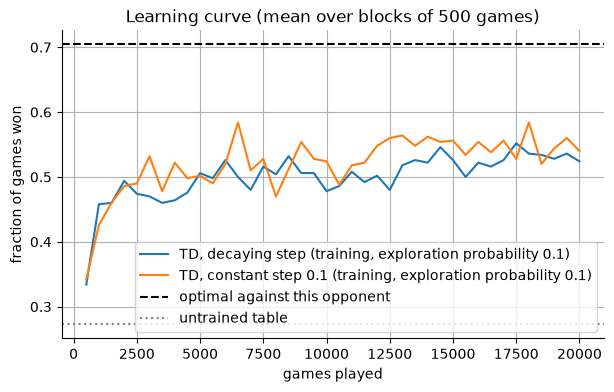

In [6]:
rng = np.random.default_rng(SEED_TD)
V_dec, counts_dec, res_dec = train(N_GAMES, alpha_decay, P_SMART, rng)
V_const, counts_const, res_const = train(N_GAMES, alpha_const, P_SMART, rng)
start_rate = evaluate({}, 4000, P_SMART, rng)  # untrained table: takes a win when it sees one, otherwise random
rate_dec, rate_const = evaluate(V_dec, 4000, P_SMART, rng), evaluate(V_const, 4000, P_SMART, rng)


def mean_abs_error(V: dict, boards: list) -> float:
    return float(np.mean([abs(V[b] - v_star(b, P_SMART)) for b in boards]))


seen = [b for b in counts_dec if min(counts_dec[b], counts_const.get(b, 0)) >= 30 and terminal_value(b) is None]
print(f"Untrained table: {start_rate:.3f}; optimal: {V_OPT:.3f}")
print(f"Greedy win rate after {N_GAMES} games: decaying step {rate_dec:.3f}, constant step {rate_const:.3f}")
print(f"Training win rate over the last {2 * BLOCK} games (with exploration): decaying {res_dec[-2 * BLOCK:].mean():.3f}, constant {res_const[-2 * BLOCK:].mean():.3f}")
print(
    f"Mean absolute error vs the exact value on {len(seen)} boards updated 30+ times by both learners: "
    f"decaying {mean_abs_error(V_dec, seen):.3f}, constant {mean_abs_error(V_const, seen):.3f}"
)
print("Checkpoint: both learners beat the untrained table:", min(rate_dec, rate_const) > start_rate)
print(f"Value of the empty starting board: decaying {V_dec[EMPTY_BOARD]:.3f}, constant {V_const[EMPTY_BOARD]:.3f}, exact {V_OPT:.3f}")

fig, ax = plt.subplots()
x = np.arange(1, len(block_means(res_dec)) + 1) * BLOCK
ax.plot(x, block_means(res_dec), label=f"TD, decaying step (training, exploration probability {EPS})")
ax.plot(x, block_means(res_const), label=f"TD, constant step {ALPHA} (training, exploration probability {EPS})")
ax.axhline(V_OPT, color="k", ls="--", label="optimal against this opponent")
ax.axhline(start_rate, color="gray", ls=":", label="untrained table")
ax.set(xlabel="games played", ylabel="fraction of games won", title="Learning curve (mean over blocks of 500 games)")
ax.legend()
plt.show()

### Reading the result

- Both learners climb from the untrained table's 0.273 (it takes a win when it sees one, otherwise plays at random) to a greedy win rate of 0.646 (decaying step) and 0.663 (constant step) after 20,000 games, against an optimum of 0.704. Neither reaches the optimum within this budget.
- The plot shows the training win rate per block of 500 games against the optimum and the untrained level. Its last 1,000 games average 0.530 (decaying) and 0.550 (constant), below the greedy rates because training includes the 10% exploratory moves.
- The learned values are close to the exact ones: on the 167 boards that both learners updated at least 30 times, the mean absolute error is 0.041 with the decaying step and 0.056 with the constant step. The empty starting board is valued at 0.680 (decaying) and 0.700 (constant) against the exact 0.704.
- The decaying step gives the more accurate table in this run, consistent with the chapter's statement that the values converge when the step size is reduced properly. The constant step's higher greedy win rate (0.663 against 0.646) comes from a single run per step size, so the notebook draws no conclusion from it.

## 4. Evolutionary policy search as a contrast

The chapter contrasts value learning with evolutionary methods, which search policy space directly: hold a
policy fixed, play many games, and use only the final outcomes to decide which policy to try next.
The simplest such method is hill climbing: a policy is a table from boards to moves, and each round changes the move for
one board and keeps the change if the win rate measured over `GAMES_PER_POLICY` games is not lower.
Boards without an entry use the same default as the untrained table above (take a win when one exists, otherwise play at random).
The climber gets the same total number of games as the TD player and sees only wins and losses, not individual states.

In [7]:
def play_policy(policy, p_smart, rng, faced):
    """One game with a fixed move table; the boards we faced are appended to `faced`."""
    b = EMPTY_BOARD
    while True:
        dist = opponent_dist(b, p_smart)
        b = play(b, rng.choice(list(dist), p=list(dist.values())), O)
        t = terminal_value(b)
        if t is not None:
            return t
        legal = moves(b)
        faced.append(b)
        wins = [j for j in legal if winner(play(b, j, X)) == X]
        i = policy.get(b, wins[0] if wins else legal[rng.integers(len(legal))])
        b = play(b, i, X)
        t = terminal_value(b)
        if t is not None:
            return t


def hill_climb(n_games, p_smart, rng):
    policy, faced = {}, []
    current = np.mean([play_policy(policy, p_smart, rng, faced) for _ in range(GAMES_PER_POLICY)])
    used, history = GAMES_PER_POLICY, [current]
    while used + GAMES_PER_POLICY <= n_games:
        cand, new_faced = dict(policy), []
        b = faced[rng.integers(len(faced))]
        cand[b] = moves(b)[rng.integers(len(moves(b)))]
        score = np.mean([play_policy(cand, p_smart, rng, new_faced) for _ in range(GAMES_PER_POLICY)])
        used += GAMES_PER_POLICY
        if score >= current:
            policy, current, faced = cand, score, new_faced or faced
        history.append(current)
    return policy, history


def evaluate_policy(policy, n_games, p_smart, rng) -> float:
    return float(np.mean([play_policy(policy, p_smart, rng, []) for _ in range(n_games)]))


rng = np.random.default_rng(SEED_EVO)
policy, history = hill_climb(N_GAMES, P_SMART, rng)
rate_evo = evaluate_policy(policy, 4000, P_SMART, rng)
print(f"Hill climbing, {N_GAMES} games ({len(history)} policies measured): {history[-1]:.3f} measured during the search, {rate_evo:.3f} on fresh games")
print(f"The shared starting policy wins {start_rate:.3f}; TD with decaying step {rate_dec:.3f}; optimal {V_OPT:.3f}")
print("Checkpoint: hill climbing stays far below TD:", rate_evo < rate_dec - 0.3)

Hill climbing, 20000 games (200 policies measured): 0.410 measured during the search, 0.294 on fresh games
The shared starting policy wins 0.273; TD with decaying step 0.646; optimal 0.704
Checkpoint: hill climbing stays far below TD: True


### Reading the result

- With the same 20,000 games the hill climber ends with a policy that wins 0.294 of fresh games, against 0.273 for the shared starting policy and 0.646 for TD with the decaying step.
- During the search it measured 0.410 for its current policy, against 0.294 on fresh games. Each accepted change had to beat a noisy 100-game score kept from an earlier acceptance, so the bar is the best of many noisy measurements, and a one-board change moves the true win rate by much less than the noise of 100 games (a standard deviation of about 0.05 near a win rate of 0.3, from the binomial formula, not a number from the book).
- Part of the gap is the weakness of this simple climber (200 candidates, the incumbent never re-measured). The comparison illustrates what judging policies by final outcomes costs; it does not show that evolutionary methods cannot work, and the chapter itself says they can be effective when the policy space is small or well structured.

## 5. An opponent that changes

The chapter says that a player whose step size is not reduced to zero also plays well against opponents that slowly
change. Here the change is abrupt: after half of the training the opponent becomes much stricter, its probability
of a winning or blocking move rising from `P_SMART` to `P_AFTER`. For each step size, a learner keeps training for as
long again while a copy stops learning at the change; both play greedily against the new opponent and are compared with
the new optimum, over `N_SEEDS` runs (sd below means standard deviation across runs).

Optimal win rate: 0.704 against the old opponent, 0.500 against the new one
decaying step: frozen at the change 0.375 (sd 0.056), kept training 0.473 (sd 0.012), mean gain 0.098 over 5 runs
constant step: frozen at the change 0.349 (sd 0.038), kept training 0.413 (sd 0.023), mean gain 0.064 over 5 runs
Checkpoint: on average, kept training beat the frozen copy for both step sizes: True


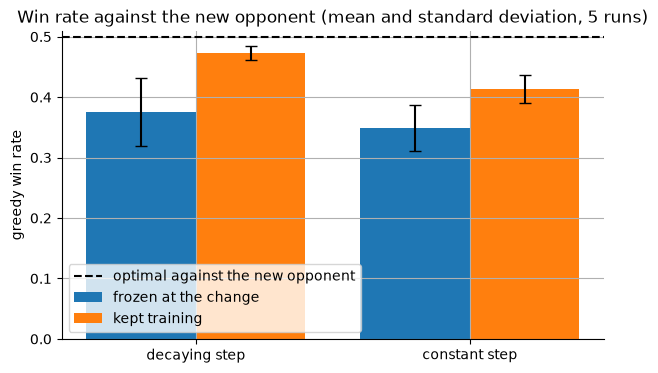

In [8]:
v_opt_after = v_star(EMPTY_BOARD, P_AFTER)


def opponent_change(seed: int):
    """Greedy win rates against the new opponent for each step size: (frozen copy, kept training)."""
    rng = np.random.default_rng(seed)
    out = []
    for alpha_fn in (alpha_decay, alpha_const):
        V, counts, _ = train(N_GAMES // 2, alpha_fn, P_SMART, rng)
        frozen = evaluate(V, 2000, P_AFTER, rng)  # `evaluate` does not learn, so this is the table as it was at the change
        train(N_GAMES // 2, alpha_fn, P_AFTER, rng, V, counts)  # counts carry over: the decaying step keeps shrinking
        out.append((frozen, evaluate(V, 2000, P_AFTER, rng)))
    return out


change = np.array([opponent_change(SEED_CHANGE + s) for s in range(N_SEEDS)])  # runs x step size x (frozen, kept training)
labels = ["decaying step", "constant step"]
print(f"Optimal win rate: {V_OPT:.3f} against the old opponent, {v_opt_after:.3f} against the new one")
for k, label in enumerate(labels):
    frozen, kept = change[:, k, 0], change[:, k, 1]
    print(
        f"{label}: frozen at the change {frozen.mean():.3f} (sd {frozen.std(ddof=1):.3f}), "
        f"kept training {kept.mean():.3f} (sd {kept.std(ddof=1):.3f}), "
        f"mean gain {np.mean(kept - frozen):.3f} over {N_SEEDS} runs"
    )
print("Checkpoint: on average, kept training beat the frozen copy for both step sizes:", bool((change[:, :, 1].mean(axis=0) > change[:, :, 0].mean(axis=0)).all()))

fig, ax = plt.subplots()
pos = np.arange(2)
ax.bar(pos - 0.2, change[:, :, 0].mean(axis=0), 0.4, yerr=change[:, :, 0].std(axis=0, ddof=1), capsize=4, label="frozen at the change")
ax.bar(pos + 0.2, change[:, :, 1].mean(axis=0), 0.4, yerr=change[:, :, 1].std(axis=0, ddof=1), capsize=4, label="kept training")
ax.axhline(v_opt_after, color="k", ls="--", label="optimal against the new opponent")
ax.set(xticks=pos, xticklabels=labels, ylabel="greedy win rate", title=f"Win rate against the new opponent (mean and standard deviation, {N_SEEDS} runs)")
ax.legend()
plt.show()

### Reading the result

- Against the new opponent the best possible win rate is 0.500. With the decaying step, a table frozen at the change wins 0.375 and the learner that keeps training reaches 0.473; with the constant step the numbers are 0.349 and 0.413 (means over 5 runs; the standard deviations are in the output). Both learners gain from further training, 0.098 and 0.064 on average.
- The constant step does not adapt better here: the decaying learner, whose step size is already small at the change, still ends higher. This notebook therefore does not reproduce an advantage of the constant step. The chapter's remark concerns opponents that change slowly, while this switch is abrupt, so the test neither confirms nor contradicts it.

## 6. Checkpoints

In [9]:
checks = [
    ("optimal win probability is a proper probability", 0 < V_OPT < 1),
    ("both TD learners beat the untrained table by 0.3 or more", min(rate_dec, rate_const) > start_rate + 0.3),
    ("the decaying-step TD player is within 0.08 of the optimum", rate_dec > V_OPT - 0.08),
    ("learned start value is within 0.03 of the exact value (decaying step)", abs(V_dec[EMPTY_BOARD] - V_OPT) < 0.03),
    ("the decaying step gives the smaller value error", mean_abs_error(V_dec, seen) < mean_abs_error(V_const, seen)),
    ("hill climbing gains under 0.1 on its starting policy, TD is far ahead", rate_evo < start_rate + 0.1 and rate_dec > rate_evo + 0.3),
    ("continuing to learn beats a frozen table after the opponent changes", bool((change[:, :, 1].mean(axis=0) > change[:, :, 0].mean(axis=0)).all())),
]
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)

print(f"\n{'player':<28}{'win rate':>9}")
for name, rate in [("starting policy", start_rate), ("hill climbing", rate_evo),
                   ("TD, constant step", rate_const), ("TD, decaying step", rate_dec), ("optimal (exact)", V_OPT)]:
    print(f"{name:<28}{rate:>9.3f}")

PASS optimal win probability is a proper probability
PASS both TD learners beat the untrained table by 0.3 or more
PASS the decaying-step TD player is within 0.08 of the optimum
PASS learned start value is within 0.03 of the exact value (decaying step)
PASS the decaying step gives the smaller value error
PASS hill climbing gains under 0.1 on its starting policy, TD is far ahead
PASS continuing to learn beats a frozen table after the opponent changes

player                       win rate
starting policy                 0.273
hill climbing                   0.294
TD, constant step               0.663
TD, decaying step               0.646
optimal (exact)                 0.704
